In [1]:
from transformers import AutoTokenizer
import torch
import os
import pandas as pd
import numpy as np
import pickle
import glob
import re
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from tqdm.notebook import tqdm
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import string
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.formula.api import mixedlm
from sklearn.metrics import r2_score
import itertools
import sys
import joblib
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list
from utils import calculate_cross_entropy,normalize_entropy,model_to_path_dict
from split_event_by_timing import align_timing_with_text
from analyze_uniform_encoding import get_pairwise_event_explained_ce

In [2]:
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

In [31]:
factor = 1.5
shrink_window = 10
calibration_temp = None
use_shrink = False # use shrink dataset to select params
use_shrink_suffix = '__use_shrink' if use_shrink else ''
save_dir = '../../generated'
sr_save_dir = '../../exp2/generated'
timing_dir = '../../behavior_data/transcripts/timing'
original_transcript_dir = '../../behavior_data/transcripts/moth_stories'
preds = ['event_duration', 'event_len', 'H_event_conditioned', 'event_kl','sylber_ce']
plot_fontsize = 8
figure_save_dir = os.path.join(save_dir,'figures')
if not os.path.exists(figure_save_dir):
    os.makedirs(figure_save_dir)

In [5]:
metrics_save_dir = os.path.join(save_dir,'metrics')
composite_df_z = pd.read_csv(os.path.join(metrics_save_dir,'z_scored_metrics.csv'))
targets = np.unique(composite_df_z['target'].tolist())
composite_df_z['composite_rank'] = composite_df_z['composite'].rank()

In [6]:
def get_uniform_encoding_df(parent_save_dir,uniform_encoding_df_name,model_save_dir_name,split_df = None,sr = False):
    uniform_encoding_dfs = []
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        story_uniform_encoding_df = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_name))
        story_uniform_encoding_df['story'] = story
        uniform_encoding_dfs.append(story_uniform_encoding_df)
    all_uniform_encoding_dfs = pd.concat(uniform_encoding_dfs,ignore_index = True)
    all_uniform_encoding_dfs = all_uniform_encoding_dfs.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
    all_uniform_encoding_dfs['story_idx'] = ['Story '+str(story_to_idx_mapping[s]) for s in all_uniform_encoding_dfs['story'].values]
    
    if split_df is not None:
        all_uniform_encoding_dfs['chunk_type'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary']]
    if sr:
        all_uniform_encoding_dfs['chunk_type_sr'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary_sr']]
    return all_uniform_encoding_dfs

In [7]:
def get_split_df(save_dir_name,save_df_name_original,save_df_name_shrink,stories,save_dir,model_save_dir_name):
    all_adjusted_split_df_timing_original = []
    all_adjusted_split_df_timing_shrink = []
    for story in stories:
        pairwise_event_save_dir_adjusted = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,save_dir_name)
        adjusted_split_df_timing_original = pd.read_csv(os.path.join(pairwise_event_save_dir_adjusted,save_df_name_original))
        if 'story' not in adjusted_split_df_timing_original:
            adjusted_split_df_timing_original['story'] = story
        all_adjusted_split_df_timing_original.append(adjusted_split_df_timing_original)

        shrink_story_split_df_save_dir = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,save_dir_name+'_shrunk')
        adjusted_split_df_timing_shrink = pd.read_csv(os.path.join(shrink_story_split_df_save_dir,save_df_name_shrink))
        if 'story' not in adjusted_split_df_timing_shrink:
            adjusted_split_df_timing_shrink['story'] = story
        all_adjusted_split_df_timing_shrink.append(adjusted_split_df_timing_shrink)


    all_adjusted_split_df_timing_original = pd.concat(all_adjusted_split_df_timing_original,ignore_index = True)
    all_adjusted_split_df_timing_original['word_count'] = all_adjusted_split_df_timing_original['text'].str.split().str.len()
    all_adjusted_split_df_timing_original['word_rate'] = all_adjusted_split_df_timing_original['word_count']/all_adjusted_split_df_timing_original['Duration']

    # not that this should be a direct copy of the original except for duration related columns. the has_boundary col reflects the consensus of the original experiment, not the updated one
    all_adjusted_split_df_timing_shrink = pd.concat(all_adjusted_split_df_timing_shrink,ignore_index = True)
    all_adjusted_split_df_timing_shrink['word_count'] = all_adjusted_split_df_timing_shrink['text'].str.split().str.len()
    all_adjusted_split_df_timing_shrink['word_rate'] = all_adjusted_split_df_timing_shrink['word_count']/all_adjusted_split_df_timing_shrink['Duration']
    if 'H_event_conditioned' in all_adjusted_split_df_timing_original.columns:
        all_adjusted_split_df_timing_original = all_adjusted_split_df_timing_original.drop(columns = ['H_event_conditioned']) # drop to avoid duplicates with analyze uniform encoding. If this col exists, it's the uncalibrated version
    if 'H_event_conditioned' in all_adjusted_split_df_timing_shrink.columns:
        all_adjusted_split_df_timing_shrink = all_adjusted_split_df_timing_shrink.drop(columns = ['H_event_conditioned'])
    assert np.all(all_adjusted_split_df_timing_original['word_count']==all_adjusted_split_df_timing_shrink['word_count'])
    return all_adjusted_split_df_timing_original,all_adjusted_split_df_timing_shrink


In [8]:
def concat_split_df_with_uniform_encoding(split_df,all_uniform_encoding_dfs):
    all_concat_df = pd.concat([split_df, all_uniform_encoding_dfs], axis=1)
    assert 'H_event_conditioned' not in all_concat_df.columns[all_concat_df.columns.duplicated()]
    all_concat_df = all_concat_df.loc[:, ~all_concat_df.columns.duplicated()]
    return all_concat_df

In [9]:
save_dir = '../../generated'
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
model_names = ['Llama3-8b-instruct','Llama3-8b','Llama3.2-3b-instruct','Llama3.2-3b-instruct_finetuned','mistral-7b-instruct','gemma-2-9b-it']
adjusted = True
all_models_all_concat_dfs_split_by_token = {}
all_models_all_concat_dfs_split_by_timing = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
        
    # get split dfs for both token and timing splits, original and shrinked
    split_token_save_dir_name = 'story_split_tokens_factor_%.1f_adjusted'%factor
    split_token_save_df_name_original = 'story_split_by_token_df_adjusted_sr.csv'
    split_token_save_df_name_shrink = 'story_split_by_token_df_adjusted.csv'

    split_duration_save_dir_name = 'story_split_timing_adjusted'
    split_duration_save_df_name_original = 'story_split_by_duration_df_adjusted.csv'
    split_duration_save_df_name_shrink = 'story_split_by_duration_df_adjusted.csv'

    all_adjusted_split_df_timing_original,all_adjusted_split_df_timing_shrink = get_split_df(split_duration_save_dir_name,split_duration_save_df_name_original,split_duration_save_df_name_shrink,stories,save_dir,model_save_dir_name)
    all_adjusted_split_df_token_original,all_adjusted_split_df_token_shrink = get_split_df(split_token_save_dir_name,split_token_save_df_name_original,split_token_save_df_name_shrink,stories,save_dir,model_save_dir_name)
        
    if adjusted:
        uniform_encoding_df_basename = 'uniform_encoding_df_even_split_by_tokens_factor_%.1f_adjusted'%factor
    else:
        uniform_encoding_df_basename = 'uniform_encoding_df_even_split_by_tokens_factor_%.1f'%factor
    if calibration_temp is not None:
        uniform_encoding_df_basename += '_caltemp_%.2f'%calibration_temp

    # new exp
    uniform_encoding_df_sr_original_name = uniform_encoding_df_basename+'_sr_original.csv'
    uniform_encoding_df_sr_shrink_name = uniform_encoding_df_basename+'_sr_shrink.csv'
    uniform_encoding_df_exp1_name = uniform_encoding_df_basename+'.csv' # old exp 
    all_uniform_encoding_dfs_original_split_by_token = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_original_name,model_save_dir_name,all_adjusted_split_df_token_original,sr = True)
    all_uniform_encoding_dfs_shrink_split_by_token = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_shrink_name,model_save_dir_name,all_adjusted_split_df_token_shrink, sr = True)
    all_uniform_encoding_dfs_exp1_split_by_token = get_uniform_encoding_df(save_dir,uniform_encoding_df_exp1_name,model_save_dir_name,all_adjusted_split_df_token_original)
    all_uniform_encoding_dfs_shrink_split_by_token['CRUISE_original'] = all_uniform_encoding_dfs_original_split_by_token['weighted_event_info_by_duration']

    # split by timing
    uniform_encoding_df_basename_timing = 'uniform_encoding_df_even_split_adjusted'
    uniform_encoding_df_sr_original_name_timing = uniform_encoding_df_basename_timing+'_sr_original.csv'
    uniform_encoding_df_sr_shrink_name_timing = uniform_encoding_df_basename_timing+'_sr_shrink.csv'
    uniform_encoding_df_exp1_name_timing = uniform_encoding_df_basename_timing+'.csv'
    all_uniform_encoding_dfs_original_split_by_timing = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_original_name_timing,model_save_dir_name)
    all_uniform_encoding_dfs_shrink_split_by_timing = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_shrink_name_timing,model_save_dir_name)
    all_uniform_encoding_dfs_exp1_split_by_timing = get_uniform_encoding_df(save_dir,uniform_encoding_df_exp1_name_timing,model_save_dir_name)
    all_uniform_encoding_dfs_shrink_split_by_timing['CRUISE_original'] = all_uniform_encoding_dfs_original_split_by_timing['weighted_event_info_by_duration']

    # check that the columns that don't contain recall and duration are the same 
    for col in all_uniform_encoding_dfs_original_split_by_token.columns:
        if 'mean' not in col and 'duration' not in col and 'sr' not in col and 'sylber' not in col:
            assert np.all(all_uniform_encoding_dfs_original_split_by_token[col]==all_uniform_encoding_dfs_shrink_split_by_token[col])
            assert np.all(all_uniform_encoding_dfs_original_split_by_token[col]==all_uniform_encoding_dfs_exp1_split_by_token[col])
    for col in all_uniform_encoding_dfs_original_split_by_timing.columns:
        if 'mean' not in col and 'duration' not in col and 'sylber' not in col:
            assert np.all(all_uniform_encoding_dfs_original_split_by_timing[col]==all_uniform_encoding_dfs_shrink_split_by_timing[col])
            assert np.all(all_uniform_encoding_dfs_original_split_by_timing[col]==all_uniform_encoding_dfs_exp1_split_by_timing[col])
    

    
    # split by token
    all_concat_dfs_split_by_token = {'original_exp':concat_split_df_with_uniform_encoding(all_adjusted_split_df_token_original,all_uniform_encoding_dfs_exp1_split_by_token),
                                     'original_sr':concat_split_df_with_uniform_encoding(all_adjusted_split_df_token_original,all_uniform_encoding_dfs_original_split_by_token),
                                    'shrink_sr':concat_split_df_with_uniform_encoding(all_adjusted_split_df_token_shrink,all_uniform_encoding_dfs_shrink_split_by_token)}
    # split by timing
    all_concat_dfs_split_by_timing = {'original_exp':concat_split_df_with_uniform_encoding(all_adjusted_split_df_timing_original,all_uniform_encoding_dfs_exp1_split_by_timing),
                                     'original_sr':concat_split_df_with_uniform_encoding(all_adjusted_split_df_timing_original,all_uniform_encoding_dfs_original_split_by_timing),
                                    'shrink_sr':concat_split_df_with_uniform_encoding(all_adjusted_split_df_timing_shrink,all_uniform_encoding_dfs_shrink_split_by_timing)}
    all_models_all_concat_dfs_split_by_token[model_name] = all_concat_dfs_split_by_token
    all_models_all_concat_dfs_split_by_timing[model_name] = all_concat_dfs_split_by_timing

In [10]:
memory_targets = ['mean_ER_intersect','mean_ER_intersect_recall_last', 'mean_ER_intersect_instruct','mean_ER_intersect_instruct_recall_last']

In [11]:
def stack_preds_from_stories(pred_dict,stories):
    stacked_preds = []
    for story in stories:
        stacked_preds.append(pred_dict[story])
    return np.concat(stacked_preds)

In [12]:
def get_capacity_preds(parent_save_dir,capacity_model_dict_name,model_save_dir_name):
    all_stories_capacity_model_dict = None
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        with open(os.path.join(uniform_encoding_save_dir,capacity_model_dict_name),'rb') as f:
            capacity_model_dict = pickle.load(f)
        exponential_uniform_encoding_dict = capacity_model_dict['exponential_uniform_encoding']
        if not all_stories_capacity_model_dict: # check if empty
            all_stories_capacity_model_dict = {c:[] for c in list(exponential_uniform_encoding_dict.keys())}
        for c in exponential_uniform_encoding_dict.keys():
            all_stories_capacity_model_dict[c].extend(exponential_uniform_encoding_dict[c])
    for c in all_stories_capacity_model_dict.keys():
        all_stories_capacity_model_dict[c] = np.array(all_stories_capacity_model_dict[c])
        
    return all_stories_capacity_model_dict,list(exponential_uniform_encoding_dict.keys())

In [16]:
# duration saturation model 
def get_saturation_duration_pred(uniform_encoding_df_exp1_name,uniform_encoding_df_sr_original_name,uniform_encoding_df_sr_shrink_name):
    all_models_saturation_duration_pred_dict = {}
    for model_name in model_names:
        model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
        caltemp_suffix = '_caltemp_%.2f'%calibration_temp if calibration_temp is not None else ''
        capacity_model_dict_exp1_name = uniform_encoding_df_exp1_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
        capacity_model_dict_exp1_name = capacity_model_dict_exp1_name.replace('.csv','.pkl')
        
        capacity_model_dict_sr_original_name = uniform_encoding_df_sr_original_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
        capacity_model_dict_sr_original_name = capacity_model_dict_sr_original_name.replace('.csv','.pkl')
        
        capacity_model_dict_sr_shrink_name = uniform_encoding_df_sr_shrink_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
        capacity_model_dict_sr_shrink_name = capacity_model_dict_sr_shrink_name.replace('.csv','.pkl')
        
        capacity_model_dict_exp1,taus = get_capacity_preds(save_dir,capacity_model_dict_exp1_name,model_save_dir_name)
        capacity_model_dict_sr_original,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_original_name,model_save_dir_name)
        capacity_model_dict_sr_shrink,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_shrink_name,model_save_dir_name)

        all_models_saturation_duration_pred_dict[model_name] = {'original_exp':capacity_model_dict_exp1,
                                                    'original_sr':capacity_model_dict_sr_original,
                                                    'shrink_sr':capacity_model_dict_sr_shrink}
    return all_models_saturation_duration_pred_dict,taus

In [17]:
all_models_saturation_duration_pred_dict,taus =get_saturation_duration_pred(uniform_encoding_df_exp1_name,uniform_encoding_df_sr_original_name,uniform_encoding_df_sr_shrink_name)
all_models_saturation_duration_pred_dict_split_by_timing,taus =get_saturation_duration_pred(uniform_encoding_df_exp1_name_timing,uniform_encoding_df_sr_original_name_timing,uniform_encoding_df_sr_shrink_name_timing)

In [18]:
taus

[np.float64(2.5),
 np.float64(3.75),
 np.float64(5.0),
 np.float64(6.25),
 np.float64(7.5),
 np.float64(8.75),
 np.float64(10.0)]

In [19]:
plotting_label_dict = {
    "weighted_event_info": "CRUISE (Number of tokens)",
    "weighted_event_info_by_duration": "CRUISE (Duration)", 
    "weighted_event_info_conditioned": "Surprisal-weighted sampling",
    "weighted_event_info_kl":"KL-weighted sampling", 
    "weighted_event_info_sylber_ce": "Acoustic surprisal-weighted sampling",
    "weighted_event_info_by_shared_info":"Shared info weighted sampling",
    'H_event_conditioned': "Surprisal",
    'H_event': "Total information",
    'event_duration': "Duration",
    "event_len": "Number of tokens",
    "chunk_type":"Event boundary",
    "event_kl":"Relative entropy",
    "chunk_type":"Event boundary",
    "chunk_type_sr":"Event boundary",
    "sylber_ce":"Acoustic surprisal",
    "weighted_event_info_exponential_saturation":"CRUISE (Duration with saturation)",
    "CRUISE_original":"CRUISE original",
    "recall":"Mean Î(Window i;R)"
}

plotting_label_dict_sm = {
    "weighted_event_info_by_duration": "CRUISE", 
    "weighted_event_info_conditioned": "Surprisal-weighted sampling",
    'H_event_conditioned': "Surprisal",
    'H_event': "Total information",
    'event_duration': "Duration",
    "event_len": "Number of tokens",
    "event_kl":"Relative entropy",
    "sylber_ce":"Acoustic surprisal",
    "weighted_event_info_sylber_ce": "Acoustic surprisal-weighted sampling",
    "weighted_event_info_kl":"KL-weighted sampling", 
    "weighted_event_info_exponential_saturation":"CRUISE (Saturation)",
}

uniform_preds = ['weighted_event_info_by_duration','weighted_event_info_exponential_saturation','weighted_event_info','weighted_event_info_conditioned','weighted_event_info_kl','weighted_event_info_sylber_ce']
controls = ['H_event_conditioned','H_event','event_kl','event_len','event_duration','sylber_ce']
uniform_preds_punctuated = uniform_preds +['weighted_event_info_conditioned_punctuated','weighted_event_info_kl_punctuated']
controls_punctuated = controls +['event_kl_punctuated','event_surprisal_punctuated']

all_preds = uniform_preds+controls
all_preds_main = ['weighted_event_info_by_duration','weighted_event_info_conditioned']+controls
uniform_preds_colors = {p:sns.color_palette("light:#005F5F_r", len(uniform_preds)+1)[i] for i,p in enumerate(uniform_preds)}
controls_colors= {p:sns.color_palette("light:#FFBF00", len(controls)+1)[i+1] for i,p in enumerate(controls)}
all_colors = {**uniform_preds_colors, **controls_colors}
all_colors.update({'chunk_type': "#ad8ec0"})
all_colors['CRUISE_original'] = all_colors['weighted_event_info_by_duration']

all_colors_labels = dict((plotting_label_dict[key], value) for (key, value) in all_colors.items())
all_preds_mini = ['weighted_event_info_by_duration','weighted_event_info_exponential_saturation','weighted_event_info_conditioned','weighted_event_info_kl','H_event_conditioned','H_event','event_len','event_duration']

In [20]:
def plot_bar_r2(model_r2_df,title):
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    colors = [all_colors[p] for p in model_r2_df['pred']]
    fig,ax = plt.subplots(figsize = (3,3))
    bars = ax.barh(model_r2_df['pred_labels'][::-1], model_r2_df['r2'][::-1],  color=colors[::-1], edgecolor='black',alpha = 0.6)
    #ax.set_title(model_plotting_names[model],fontsize =17)
    ax.set_yticks(model_r2_df['pred_labels'][::-1])
    ax.set_yticklabels(model_r2_df['pred_labels'][::-1],fontsize = plot_fontsize)
    ax.set_xlabel(r'$R^2$',fontsize = plot_fontsize)
    ax.set_title(title,fontsize=plot_fontsize)
    sns.despine()
    ax.tick_params(axis='y', length=0) # hides ticks 

    plt.show()


In [21]:
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_heatmap_with_strips(df, all_preds, plotting_label_dict,
                            model_colors,savepath = None):

    df = df.copy()

    # --- build matrix
    mat = df.pivot_table(
        index='pred',
        columns='composite_rank',
        values='rank'
    )

    mat = mat.reindex(all_preds)
    mat = mat.sort_index(axis=1)

    # clean labels
    mat.columns = mat.columns.round().astype(int)
    mat.index = [plotting_label_dict.get(p, p) for p in mat.index]

    # --- extract column-wise metadata (aligned with columns)
    col_meta = (
        df.sort_values('composite_rank')
          .drop_duplicates('composite_rank')
          .set_index('composite_rank')
          .loc[mat.columns]
    )

    col_models = col_meta['model'].values

    # --- define method categories
    def get_method(row):
        recall = 'Recall_last' if '_recall_last' in row['target'] else 'Recall_first'
        tuning = 'Instruction prompted' if '_instruct' in row['target'] else 'Direct concatenation'
        return (recall, tuning)

    col_methods = [get_method(row) for _, row in col_meta.iterrows()]

    # --- method colors (structured: hue=recall, lightness=tuning)
    method_colors = {
        ('Recall_first', 'Direct concatenation'):  '#D7B9C4',  # Dusty Mauve
        ('Recall_first', 'Instruction prompted'):   '#601A35',  # Deep Wine

        ('Recall_last',  'Direct concatenation'):  '#E8BDD2',  # Softened Muted Rose
        ('Recall_last',  'Instruction prompted'):   '#A64D79',  # Sophisticated Muted Berry
    }

    # --- convert to RGB arrays
    model_color_row = np.array([to_rgb(model_colors[m]) for m in col_models])
    method_color_row = np.array([to_rgb(method_colors[m]) for m in col_methods])

    strip = np.stack([method_color_row, model_color_row])  # (2, N, 3)

    
    # Convert to numpy to avoid pandas IndexingErrors
    mat_values = mat.values 

    # 1. Create an empty annotation matrix
    annot_mat = np.full(mat_values.shape, "", dtype=object)

    # 2. Iterate through each column
    for col_idx in range(mat_values.shape[1]):
        # Use the numpy array for slicing
        col_data = mat_values[:, col_idx]

        # Get indices of the 3 smallest values
        top_4_indices = np.argsort(col_data)[:4]

        for row_idx in top_4_indices:
            rank_val = mat_values[row_idx, col_idx]
            annot_mat[row_idx, col_idx] = f"{int(rank_val)}"   
    # --- plot
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.heatmap(
        mat,
        ax=ax,
        annot=annot_mat,          # Pass our custom string matrix
        fmt="",                   # Tell seaborn not to try to format strings as floats
        annot_kws={'fontsize': plot_fontsize, 'fontweight': 'bold'},
        cmap=sns.color_palette("Purples_r", n_colors=len(np.unique(mat))),
        cbar_kws={"ticks": np.unique(mat)}
    )
    cbar = ax.collections[0].colorbar
    cbar.set_label(r'$r^2$ Rank (lower = better)', fontsize=plot_fontsize)

    ax.set_xlabel('Composite metric rank (lower = better)',fontsize = plot_fontsize)
    ax.set_ylabel('Predictor',fontsize = plot_fontsize)
    ax.tick_params(axis='y', labelsize=plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)

    # --- add strip 
    ax_strip = ax.inset_axes([0, 1.05, 1, 0.12])  # [x, y, width, height]
    ax_strip.imshow(strip, aspect='auto')
    ax_strip.set_xticks([])
    ax_strip.set_yticks([0, 1])
    ax_strip.set_yticklabels(['Method', 'Model'],fontsize = plot_fontsize)

    # --- legends
    # model legend
    model_handles = [
        Patch(facecolor=c, edgecolor='none', label=m)
        for m, c in model_colors.items()
    ]

    # method legend
    method_handles = [
        Patch(facecolor=method_colors[k], edgecolor='none',
              label=f"{k[0].replace('_',' ')}, {k[1]}")
        for k in method_colors
    ]

    fig.legend(handles=model_handles, title="Model",
               loc='upper left', bbox_to_anchor=(1.02, 1))

    fig.legend(handles=method_handles, title="Estimation method",
               loc='upper left', bbox_to_anchor=(1.02, 0.35))

    sns.despine()
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, transparent = True)
    plt.show()

## split by tokens

In [22]:
pred = 'weighted_event_info_exponential_saturation'
all_models_best_tau = []
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    fit_df = all_concat_dfs_split_by_token['original_exp'].copy()
    pred_dict = all_models_saturation_duration_pred_dict[model_name]['original_exp']
    pred_dict_shrink = all_models_saturation_duration_pred_dict[model_name]['shrink_sr']
    for target in memory_targets:
        saturation_model_results = []
        for tau in taus:
            fit_df[pred] = pred_dict[tau]
            fit = ols('%s ~ %s+%s:C(story)'%(target,pred,pred), data=fit_df).fit() 
            adj_r2 = fit.rsquared_adj
            saturation_model_results.append([tau,adj_r2])
        saturation_model_results = pd.DataFrame(saturation_model_results,columns = ['tau','adj_r2'])
        idx = np.argmax(saturation_model_results['adj_r2'].values)
        best_tau = taus[idx]
        all_concat_dfs_split_by_token['original_exp'][pred+'_'+target] = pred_dict[best_tau]
        all_concat_dfs_split_by_token['original_sr'][pred+'_'+target] = pred_dict[best_tau]
        all_concat_dfs_split_by_token['shrink_sr'][pred+'_'+target] = pred_dict_shrink[best_tau]
        all_models_best_tau.append([model_name,target,best_tau])
all_models_best_tau = pd.DataFrame(all_models_best_tau,columns = ['model','target','best_tau'])

In [339]:
all_models_best_tau.to_csv(os.path.join(metrics_save_dir,'all_models_best_tau.csv'),index = False)

In [24]:
all_models_best_tau

,model,target,best_tau
0,Llama3-8b-instruct,mean_ER_intersect,6.25
1,Llama3-8b-instruct,mean_ER_intersect_recall_last,2.50
2,Llama3-8b-instruct,mean_ER_intersect_instruct,7.50
3,Llama3-8b-instruct,mean_ER_intersect_instruct_recall_last,2.50
4,Llama3-8b,mean_ER_intersect,2.50
5,Llama3-8b,mean_ER_intersect_recall_last,10.00
6,Llama3-8b,mean_ER_intersect_instruct,2.50
7,Llama3-8b,mean_ER_intersect_instruct_recall_last,10.00
8,Llama3.2-3b-instruct,mean_ER_intersect,2.50
9,Llama3.2-3b-instruct,mean_ER_intersect_recall_last,2.50


In [25]:
# use the taus for split by tokens for split by timing
pred = 'weighted_event_info_exponential_saturation'
all_models_best_tau_timing = []
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_timing = all_models_all_concat_dfs_split_by_timing[model_name]
    fit_df = all_concat_dfs_split_by_timing['original_exp'].copy()
    pred_dict = all_models_saturation_duration_pred_dict_split_by_timing[model_name]['original_exp']
    pred_dict_shrink = all_models_saturation_duration_pred_dict_split_by_timing[model_name]['shrink_sr']
    for target in memory_targets:
        saturation_model_results = []
        for tau in taus:
            fit_df[pred] = pred_dict[tau]
            fit = ols('%s ~ %s+%s:C(story)'%(target,pred,pred), data=fit_df).fit() 
            adj_r2 = fit.rsquared_adj
            saturation_model_results.append([tau,adj_r2])
        saturation_model_results = pd.DataFrame(saturation_model_results,columns = ['tau','adj_r2'])
        idx = np.argmax(saturation_model_results['adj_r2'].values)
        best_tau = taus[idx]
        split_by_token_best_tau = all_models_best_tau[(all_models_best_tau['model']==model_name) & (all_models_best_tau['target']==target)]['best_tau'].values[0]
        all_concat_dfs_split_by_timing['original_exp'][pred+'_'+target] = pred_dict[split_by_token_best_tau]
        all_concat_dfs_split_by_timing['original_sr'][pred+'_'+target] = pred_dict[split_by_token_best_tau]
        all_concat_dfs_split_by_timing['shrink_sr'][pred+'_'+target] = pred_dict_shrink[split_by_token_best_tau]
        all_models_best_tau_timing.append([model_name,target,best_tau])
    #     if model_name == 'Llama3-8b-instruct': # the r^2 are all really similar 
    #         print(saturation_model_results)
    # if model_name != 'Llama3-8b-instruct':
    #     continue
all_models_best_tau_timing = pd.DataFrame(all_models_best_tau_timing,columns = ['model','target','best_tau'])

In [26]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    original_models_r2_dfs = {target:{} for target in memory_targets}
    original_models_variable_g_all_preds = {target:{} for target in memory_targets}
    original_models_split_by_tokens_save_dict = {target:{} for target in memory_targets}
    for target in memory_targets:
        rsquared_list = []
        for pred in all_preds: 
            if 'exponential_saturation' in pred:
                fit = ols('%s ~ %s+%s:C(story)'%(target,pred+'_'+target,pred+'_'+target), data=all_concat_dfs_split_by_token['original_exp']).fit() 
            else:
                fit = ols('%s ~ %s+%s:C(story)'%(target,pred,pred), data=all_concat_dfs_split_by_token['original_exp']).fit() 
            original_models_variable_g_all_preds[target][pred] = fit
            #print(pred,'original data, r2 = %.4f'%fit.rsquared)
            rsquared_list.append(fit.rsquared)

            original_models_split_by_tokens_save_dict[target][pred] = {'fit': fit,
                                                              'formula':'%s ~ %s+%s:C(story)'%(target,pred,pred)}
        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list})
        original_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by tokens, %s'%model_name)
    # save models 

    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    if not os.path.exists(reg_model_save_dir):
        os.makedirs(reg_model_save_dir)
    reg_model_save_name = 'regression_even_split_by_tokens_factor_%.1f_adjusted%s_cleaned.joblib'%(factor,use_shrink_suffix) if adjusted else 'regression_even_split_by_tokens_factor_%.1f%s_cleaned.joblib'%(factor,use_shrink_suffix)
    joblib.dump(original_models_split_by_tokens_save_dict, os.path.join(reg_model_save_dir,reg_model_save_name))
    all_models_r2_dfs[model_name] = original_models_r2_dfs

In [27]:
def merge_r2_dfs_with_metrics(all_models_r2_dfs):
    all_models_adj_r2_df_original_exp= []
    for model_name in model_names:
        for target in memory_targets:
            subdf = all_models_r2_dfs[model_name][target]
            all_models_adj_r2_df_original_exp.append(subdf)
    all_models_adj_r2_df_original_exp = pd.concat(all_models_adj_r2_df_original_exp)
    all_models_adj_r2_df_original_exp['rank'] = (
        all_models_adj_r2_df_original_exp
        .groupby(['target', 'model'])['r2']
        .rank(ascending=False, method='min')
        .astype(int)
    )
    merged_rank_metrics_df_allpreds_original_exp = pd.merge(left = all_models_adj_r2_df_original_exp,right = composite_df_z,on = ['target','model'])
    return merged_rank_metrics_df_allpreds_original_exp

### exp 1

In [28]:
merged_rank_metrics_df_allpreds_original_exp = merge_r2_dfs_with_metrics(all_models_r2_dfs)

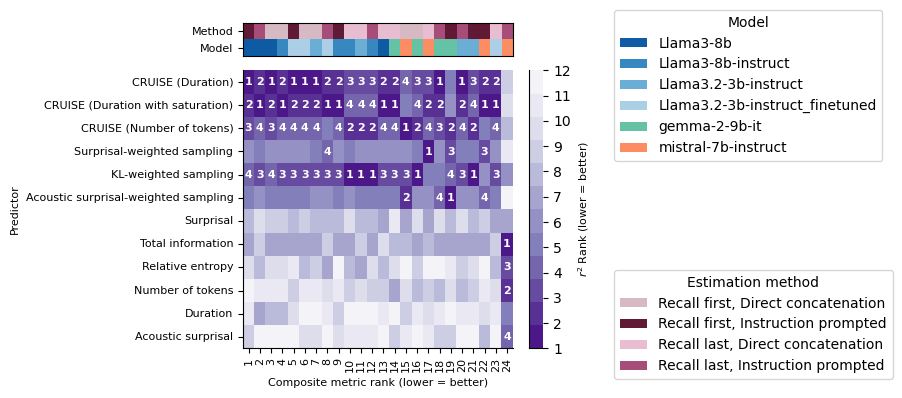

In [32]:
llama_models = [
    'Llama3-8b',
    'Llama3-8b-instruct',
    'Llama3.2-3b-instruct',
    'Llama3.2-3b-instruct_finetuned'
]
other_models = ['gemma-2-9b-it', 'mistral-7b-instruct']

llama_colors = sns.color_palette("Blues", n_colors=5)[1:][::-1]
other_colors = sns.color_palette("Set2", n_colors=2)

model_colors = {m:c for m,c in zip(llama_models+other_models, llama_colors+other_colors)}
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_tokens_adjusted_exp1.svg')
plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_original_exp, all_preds, plotting_label_dict,
                            model_colors, savepath=save_name)

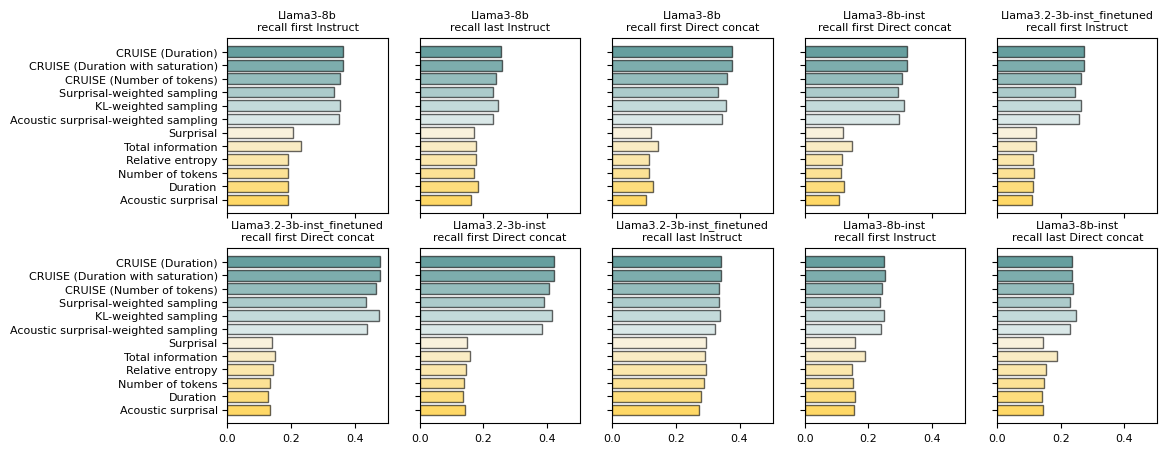

In [33]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_original_exp.loc[merged_rank_metrics_df_allpreds_original_exp['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


### exp2 control

In [34]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    reg_model_save_name = 'regression_even_split_by_tokens_factor_%.1f_adjusted%s_cleaned.joblib'%(factor,use_shrink_suffix) if adjusted else 'regression_even_split_by_tokens_factor_%.1f%s_cleaned.joblib'%(factor,use_shrink_suffix)
    original_models_split_by_tokens_save_dict = joblib.load(os.path.join(reg_model_save_dir,reg_model_save_name))

    
    sr_original_models_r2_dfs = {target:{} for target in memory_targets}


    for target in memory_targets:
        rsquared_list = []
        this_target_fit_dict = original_models_split_by_tokens_save_dict[target]
        for pred in all_preds: 
            this_target_pred_fit = this_target_fit_dict[pred]['fit']
            fit_df_sr_original = all_concat_dfs_split_by_token['original_sr']
            y_pred = this_target_pred_fit.predict(fit_df_sr_original)
            target_val = fit_df_sr_original[target]
            r2 = r2_score(target_val,y_pred)
            rsquared_list.append(r2)

        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list})
        sr_original_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by tokens, %s'%model_name)
    # save models 

    all_models_r2_dfs[model_name] = sr_original_models_r2_dfs

In [35]:
merged_rank_metrics_df_allpreds_sr_original = merge_r2_dfs_with_metrics(all_models_r2_dfs)

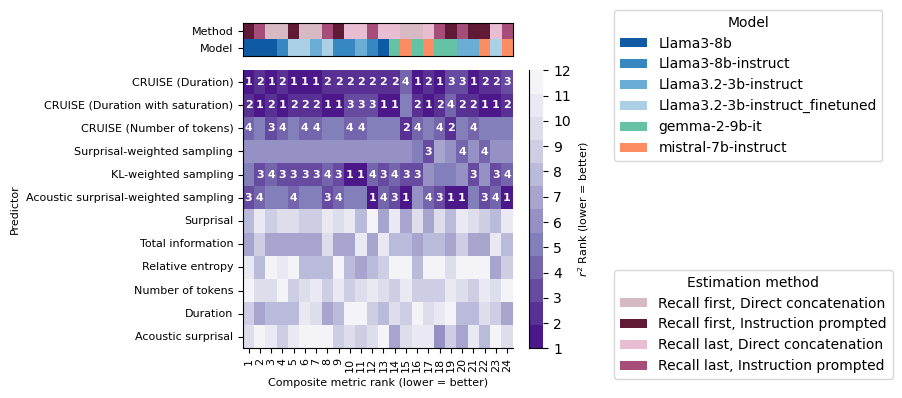

In [36]:
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_tokens_adjusted_exp2_sr_original.svg')
plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_sr_original, all_preds, plotting_label_dict,
                            model_colors, savepath=save_name)

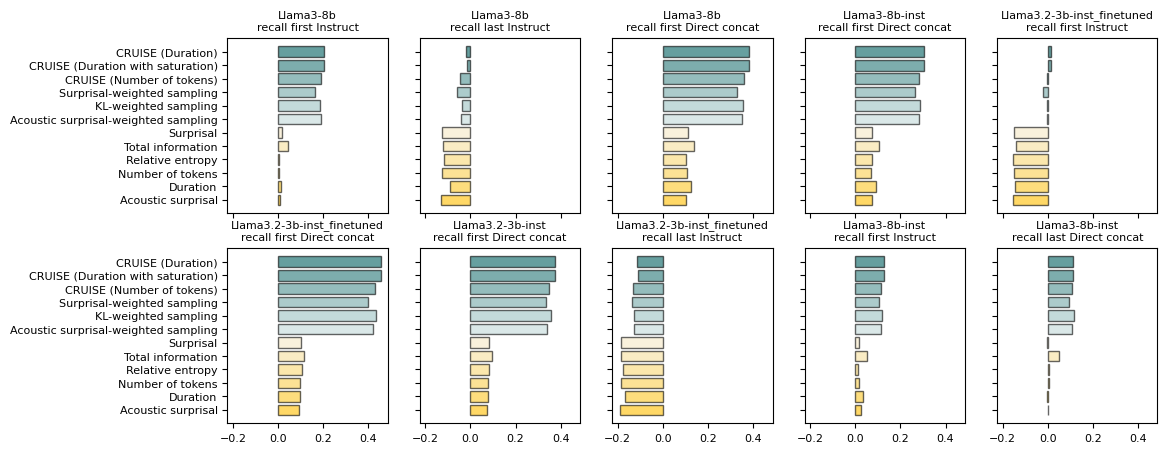

In [37]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_sr_original.loc[merged_rank_metrics_df_allpreds_sr_original['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


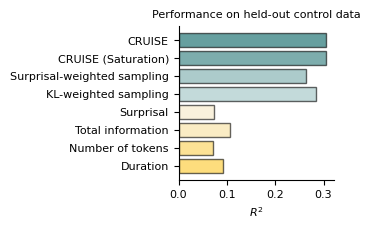

In [38]:
model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
fig,ax = plt.subplots(figsize = (2,2))
estimate_df = merged_rank_metrics_df_allpreds_sr_original.loc[merged_rank_metrics_df_allpreds_sr_original['composite_rank']==4]
estimate_df_mini = estimate_df[estimate_df['pred'].isin(all_preds_mini)].copy()
estimate_df_mini['pred_labels_sm'] = [plotting_label_dict_sm[p] for p in estimate_df_mini['pred']]
colors = [all_colors[p] for p in estimate_df_mini['pred']]
bars = ax.barh(estimate_df_mini['pred_labels_sm'][::-1], estimate_df_mini['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
model = np.unique(estimate_df_mini['model_plotting_name'])[0]
pred_labels = estimate_df_mini['pred_labels_sm']
recall_first_str = 'recall last' if 'last' in np.unique(estimate_df_mini['target'])[0] else 'recall first'
inst_str = np.unique(estimate_df_mini['version'])[0]
ax.set_title('Performance on held-out control data',fontsize =plot_fontsize)
ax.set_yticks(pred_labels[::-1])
ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
ax.tick_params(axis='x', labelsize=plot_fontsize)
ax.set_xlabel(r'$R^2$', fontsize = plot_fontsize)
sns.despine()

this_figure_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'uniform_encoding','figures_even_split_by_tokens_factor_%.1f_adjusted'%factor)
#fig.savefig(os.path.join(this_figure_save_dir,'uniform_encoding_r2_bar_%s_%s_held_out_mini.svg'%('recall first','direct concatenation')),transparent = True)

### exp 2 shrink

In [39]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    reg_model_save_name = 'regression_even_split_by_tokens_factor_%.1f_adjusted%s_cleaned.joblib'%(factor,use_shrink_suffix) if adjusted else 'regression_even_split_by_tokens_factor_%.1f%s_cleaned.joblib'%(factor,use_shrink_suffix)
    original_models_split_by_tokens_save_dict = joblib.load(os.path.join(reg_model_save_dir,reg_model_save_name))
    
    sr_shrink_models_r2_dfs = {target:{} for target in memory_targets}

    for target in memory_targets:
        rsquared_list = []
        this_target_fit_dict = original_models_split_by_tokens_save_dict[target]
        for pred in all_preds: 
            this_target_pred_fit = this_target_fit_dict[pred]['fit']
            fit_df_shrink_sr = all_concat_dfs_split_by_token['shrink_sr']
            y_pred = this_target_pred_fit.predict(fit_df_shrink_sr)
            target_val = fit_df_shrink_sr[target]
            r2 = r2_score(target_val,y_pred)
            rsquared_list.append(r2)
              
        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list})
        sr_shrink_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by tokens, %s'%model_name)
    # save models 

    all_models_r2_dfs[model_name] = sr_shrink_models_r2_dfs

In [40]:
merged_rank_metrics_df_allpreds_sr_shrink = merge_r2_dfs_with_metrics(all_models_r2_dfs)

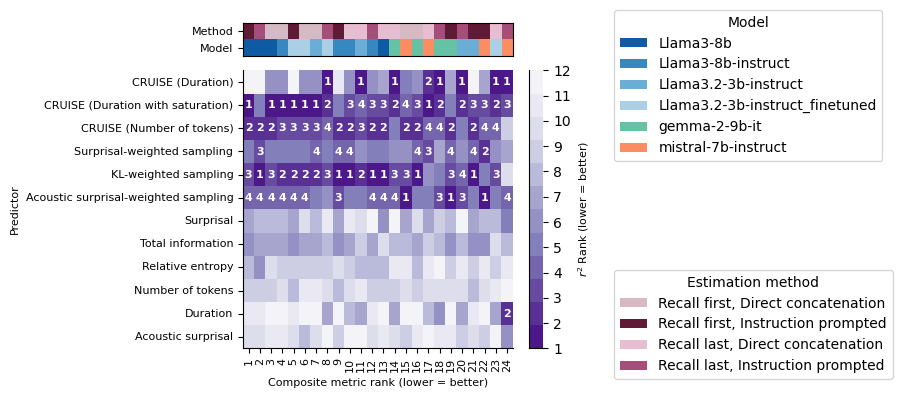

In [41]:
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_tokens_adjusted_exp2_sr_shrink.svg')

plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_sr_shrink, all_preds, plotting_label_dict,
                            model_colors, savepath=save_name)

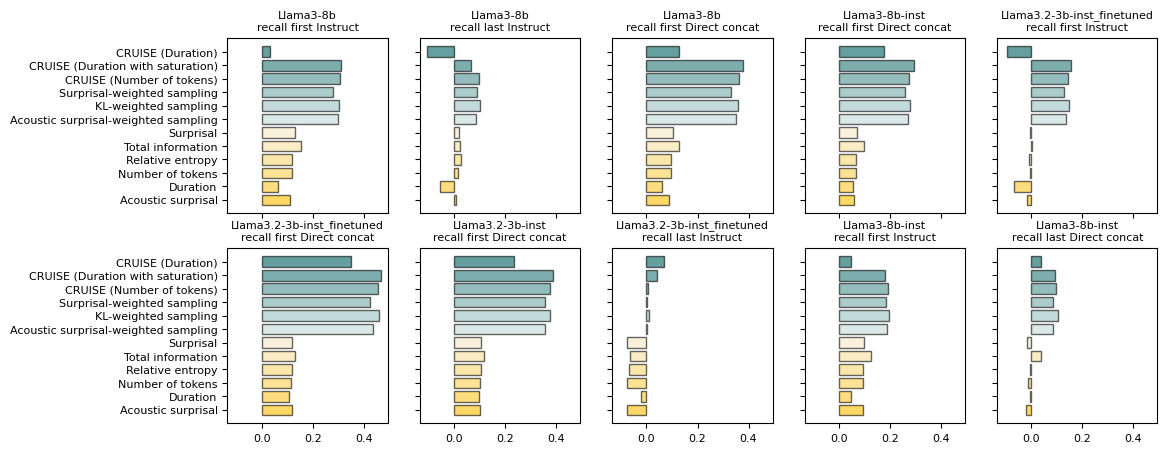

In [42]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_sr_shrink.loc[merged_rank_metrics_df_allpreds_sr_shrink['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


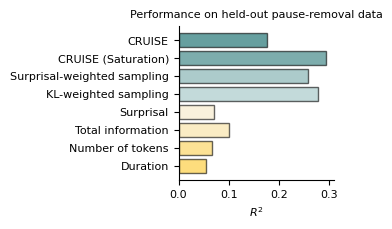

In [359]:
model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
fig,ax = plt.subplots(figsize = (2,2))
estimate_df = merged_rank_metrics_df_allpreds_sr_shrink.loc[merged_rank_metrics_df_allpreds_sr_shrink['composite_rank']==4]
estimate_df_mini = estimate_df[estimate_df['pred'].isin(all_preds_mini)].copy()
estimate_df_mini['pred_labels_sm'] = [plotting_label_dict_sm[p] for p in estimate_df_mini['pred']]
colors = [all_colors[p] for p in estimate_df_mini['pred']]
bars = ax.barh(estimate_df_mini['pred_labels_sm'][::-1], estimate_df_mini['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
model = np.unique(estimate_df_mini['model_plotting_name'])[0]
pred_labels = estimate_df_mini['pred_labels_sm']
recall_first_str = 'recall last' if 'last' in np.unique(estimate_df_mini['target'])[0] else 'recall first'
inst_str = np.unique(estimate_df_mini['version'])[0]
ax.set_title('Performance on held-out pause-removal data',fontsize =plot_fontsize)
ax.set_yticks(pred_labels[::-1])
ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
ax.set_xlabel(r'$R^2$', fontsize = plot_fontsize)
ax.tick_params(axis='x', labelsize=plot_fontsize)
sns.despine()

this_figure_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'uniform_encoding','figures_even_split_by_tokens_factor_%.1f_adjusted'%factor)
fig.savefig(os.path.join(this_figure_save_dir,'uniform_encoding_r2_bar_%s_%s_held_out_shrink_mini.svg'%('recall first','direct concatenation')),transparent = True)

## split by duration

### exp 1

In [43]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_duration = all_models_all_concat_dfs_split_by_timing[model_name]
    
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    original_models_r2_dfs = {target:{} for target in memory_targets}
    original_models_variable_g_all_preds = {target:{} for target in memory_targets}
    original_models_split_by_duration_save_dict = {target:{} for target in memory_targets}
    for target in memory_targets:
        rsquared_list = []
        adj_r2_list = []
        for pred in all_preds: 
            if 'exponential_saturation' in pred:
                fit = ols('%s ~ %s+%s:C(story)'%(target,pred+'_'+target,pred+'_'+target), data=all_concat_dfs_split_by_duration['original_exp']).fit() 
            else:
                fit = ols('%s ~ %s+%s:C(story)'%(target,pred,pred), data=all_concat_dfs_split_by_duration['original_exp']).fit() 
            original_models_variable_g_all_preds[target][pred] = fit
            #print(pred,'original data, r2 = %.4f'%fit.rsquared)
            rsquared_list.append(fit.rsquared)
            adj_r2_list.append(fit.rsquared_adj)

            original_models_split_by_duration_save_dict[target][pred] = {'fit': fit,
                                                              'formula':'%s ~ %s+%s:C(story)'%(target,pred,pred)}
        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list,
                                    'adj_r2':adj_r2_list})
        original_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by duration, %s'%model_name)
    # save models 

    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    if not os.path.exists(reg_model_save_dir):
        os.makedirs(reg_model_save_dir)
    reg_model_save_name = 'regression_even_split_adjusted%s_cleaned.joblib'%use_shrink_suffix if adjusted else 'regression_even_split%s_cleaned.joblib'%use_shrink_suffix
    joblib.dump(original_models_split_by_duration_save_dict, os.path.join(reg_model_save_dir,reg_model_save_name))
    all_models_r2_dfs[model_name] = original_models_r2_dfs

In [44]:
merged_rank_metrics_df_allpreds_original_exp_split_by_timing = merge_r2_dfs_with_metrics(all_models_r2_dfs)

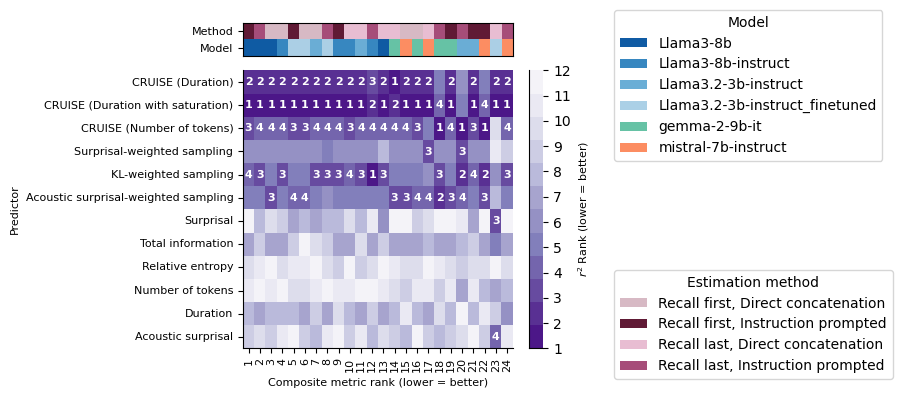

In [45]:
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_duration_adjusted_exp1.svg')

plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_original_exp_split_by_timing, all_preds, plotting_label_dict,
                            model_colors, savepath=save_name)

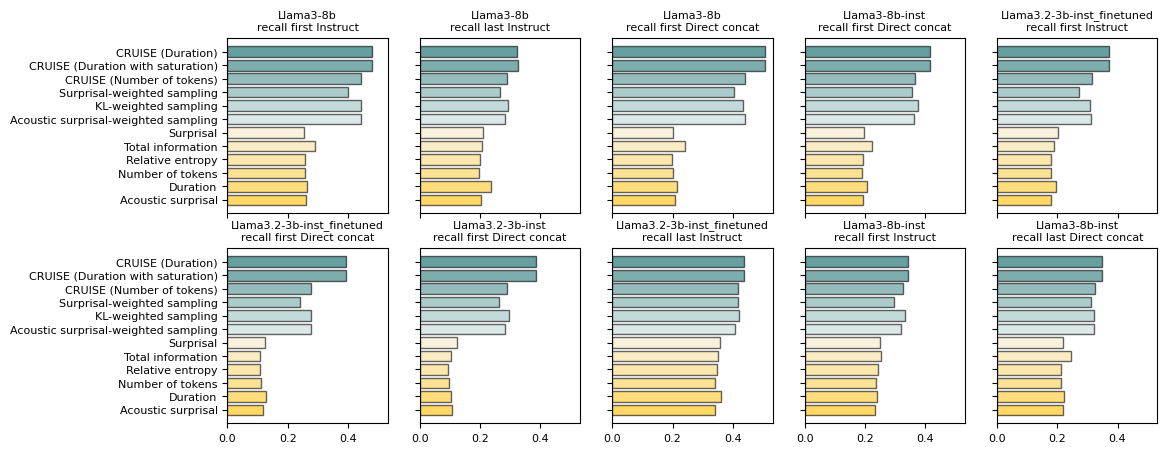

In [46]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_original_exp_split_by_timing.loc[merged_rank_metrics_df_allpreds_original_exp_split_by_timing['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


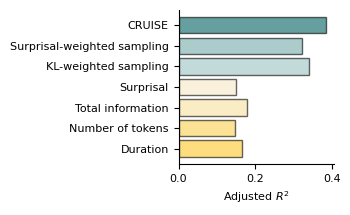

In [47]:
all_preds_mini_original = all_preds_mini.copy()
all_preds_mini_original.remove('weighted_event_info_exponential_saturation')
fig,ax = plt.subplots(figsize = (2,2))
estimate_df = merged_rank_metrics_df_allpreds_original_exp_split_by_timing.loc[merged_rank_metrics_df_allpreds_original_exp_split_by_timing['composite_rank']==4]
estimate_df_mini = estimate_df[estimate_df['pred'].isin(all_preds_mini_original)].copy()
estimate_df_mini['pred_labels_sm'] = [plotting_label_dict_sm[p] for p in estimate_df_mini['pred']]
colors = [all_colors[p] for p in estimate_df_mini['pred']]
bars = ax.barh(estimate_df_mini['pred_labels_sm'][::-1], estimate_df_mini['adj_r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
model = np.unique(estimate_df_mini['model_plotting_name'])[0]
pred_labels = estimate_df_mini['pred_labels_sm']
recall_first_str = 'recall last' if 'last' in np.unique(estimate_df_mini['target'])[0] else 'recall first'
inst_str = np.unique(estimate_df_mini['version'])[0]
#ax.set_title('Performance on held-out control data',fontsize =plot_fontsize)
ax.set_yticks(pred_labels[::-1])
ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
ax.set_xlabel(r'Adjusted $R^2$', fontsize = plot_fontsize)
ax.tick_params(axis='x', labelsize=plot_fontsize)
sns.despine()

this_figure_save_dir = os.path.join(save_dir,'llama3-8b-instruct/uniform_encoding/figures_even_split/adjusted')
fig.savefig(os.path.join(this_figure_save_dir,'uniform_encoding_r2_bar_%s_%s_mini.svg'%('recall first','direct concatenation')),transparent = True)

### exp 2 control

In [48]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_timing = all_models_all_concat_dfs_split_by_timing[model_name]
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    reg_model_save_name = 'regression_even_split_adjusted%s_cleaned.joblib'%use_shrink_suffix if adjusted else 'regression_even_split%s_cleaned.joblib'%use_shrink_suffix
    original_models_split_by_timing_save_dict = joblib.load(os.path.join(reg_model_save_dir,reg_model_save_name))

    sr_original_models_r2_dfs = {target:{} for target in memory_targets}

    for target in memory_targets:
        rsquared_list = []
        this_target_fit_dict = original_models_split_by_timing_save_dict[target]
        for pred in all_preds: 
            this_target_pred_fit = this_target_fit_dict[pred]['fit']
            fit_df_sr_original = all_concat_dfs_split_by_timing['original_sr']
            y_pred = this_target_pred_fit.predict(fit_df_sr_original)
            target_val = fit_df_sr_original[target]
            r2 = r2_score(target_val,y_pred)
            rsquared_list.append(r2)

        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list})
        sr_original_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by timing, %s'%model_name)
    # save models 

    all_models_r2_dfs[model_name] = sr_original_models_r2_dfs

In [49]:
merged_rank_metrics_df_allpreds_original_sr_split_by_timing = merge_r2_dfs_with_metrics(all_models_r2_dfs)

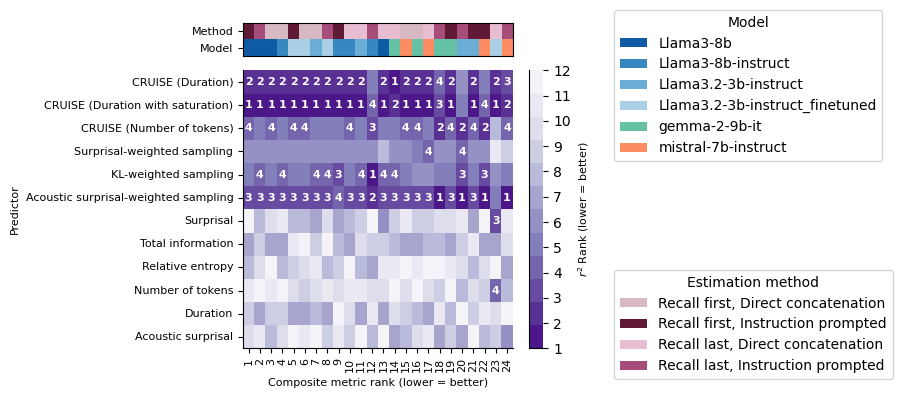

In [50]:
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_duration_adjusted_exp2_sr_original.svg')

plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_original_sr_split_by_timing, all_preds, plotting_label_dict,
                            model_colors,savepath=save_name)

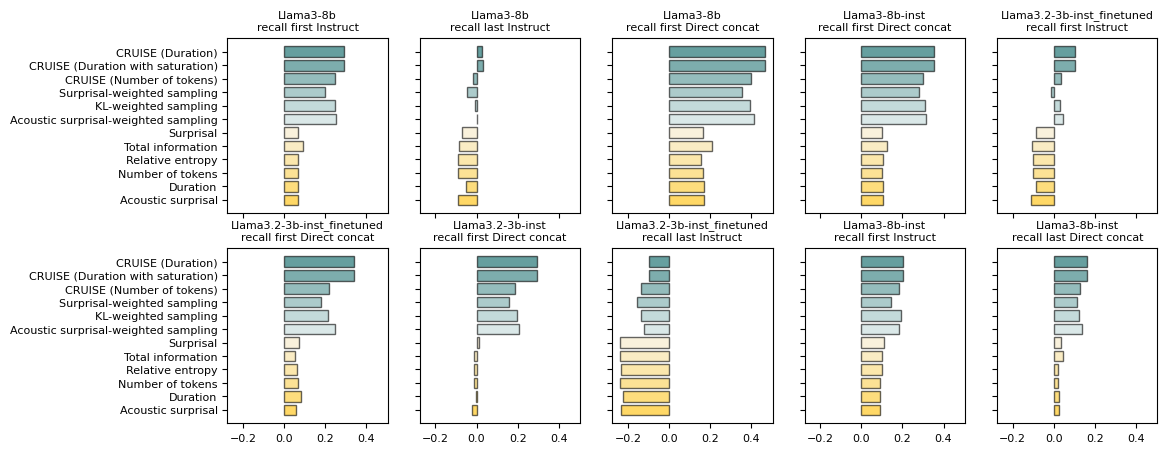

In [51]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_original_sr_split_by_timing.loc[merged_rank_metrics_df_allpreds_original_sr_split_by_timing['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


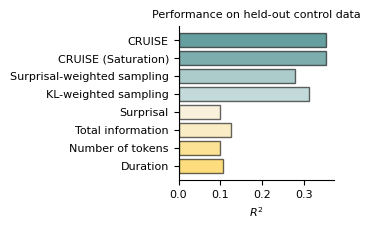

In [52]:
fig,ax = plt.subplots(figsize = (2,2))
estimate_df = merged_rank_metrics_df_allpreds_original_sr_split_by_timing.loc[merged_rank_metrics_df_allpreds_original_sr_split_by_timing['composite_rank']==4]
estimate_df_mini = estimate_df[estimate_df['pred'].isin(all_preds_mini)].copy()
estimate_df_mini['pred_labels_sm'] = [plotting_label_dict_sm[p] for p in estimate_df_mini['pred']]
colors = [all_colors[p] for p in estimate_df_mini['pred']]
bars = ax.barh(estimate_df_mini['pred_labels_sm'][::-1], estimate_df_mini['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
model = np.unique(estimate_df_mini['model_plotting_name'])[0]
pred_labels = estimate_df_mini['pred_labels_sm']
recall_first_str = 'recall last' if 'last' in np.unique(estimate_df_mini['target'])[0] else 'recall first'
inst_str = np.unique(estimate_df_mini['version'])[0]
ax.set_title('Performance on held-out control data',fontsize =plot_fontsize)
ax.set_yticks(pred_labels[::-1])
ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
ax.set_xlabel(r'$R^2$', fontsize = plot_fontsize)
ax.tick_params(axis='x', labelsize=plot_fontsize)
sns.despine()

this_figure_save_dir = os.path.join(save_dir,'llama3-8b-instruct/uniform_encoding/figures_even_split/adjusted')
fig.savefig(os.path.join(this_figure_save_dir,'uniform_encoding_r2_bar_%s_%s_held_out_mini.svg'%('recall first','direct concatenation')),transparent = True)

### exp 2 shrink

In [53]:
all_models_r2_dfs = {}
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_timing = all_models_all_concat_dfs_split_by_timing[model_name]
    pred_labels = [plotting_label_dict[p] for p in all_preds]
    reg_model_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','regression_models')
    reg_model_save_name = 'regression_even_split_adjusted%s_cleaned.joblib'%use_shrink_suffix if adjusted else 'regression_even_split%s_cleaned.joblib'%use_shrink_suffix
    original_models_split_by_timing_save_dict = joblib.load(os.path.join(reg_model_save_dir,reg_model_save_name))

    sr_shrink_models_r2_dfs = {target:{} for target in memory_targets}

    for target in memory_targets:
        rsquared_list = []
        this_target_fit_dict = original_models_split_by_timing_save_dict[target]
        for pred in all_preds: 
            this_target_pred_fit = this_target_fit_dict[pred]['fit']
            fit_df_sr_original = all_concat_dfs_split_by_timing['shrink_sr']
            y_pred = this_target_pred_fit.predict(fit_df_sr_original)
            target_val = fit_df_sr_original[target]
            r2 = r2_score(target_val,y_pred)
            rsquared_list.append(r2)

        model_r2_df = pd.DataFrame({'pred':all_preds,
                                    'pred_labels':pred_labels,
                                    'target':target,
                                    'model':model_name,
                                    'r2':rsquared_list})
        sr_shrink_models_r2_dfs[target] = model_r2_df
    #plot_bar_r2(model_r2_df,title='Original experiment, split by timing, %s'%model_name)
    # save models 

    all_models_r2_dfs[model_name] = sr_shrink_models_r2_dfs

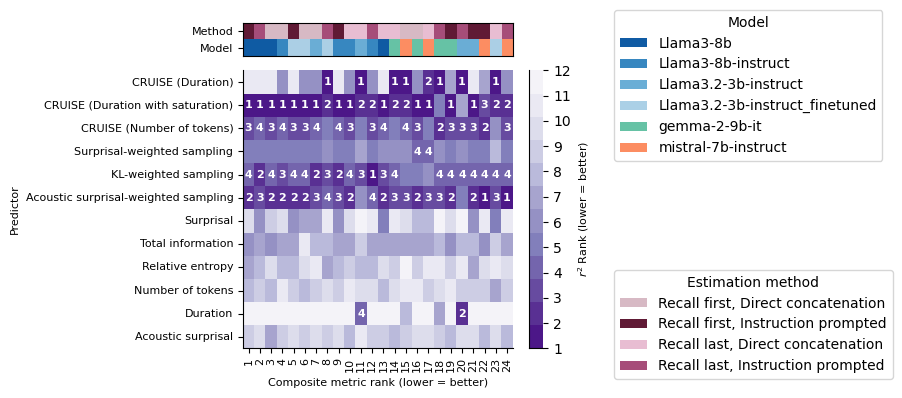

In [54]:
save_name = os.path.join(figure_save_dir,'model_universe_heatmap_split_by_duration_adjusted_exp2_sr_shrink.svg')

merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing = merge_r2_dfs_with_metrics(all_models_r2_dfs)
plot_heatmap_with_strips(merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing, all_preds, plotting_label_dict,
                            model_colors,savepath=save_name)

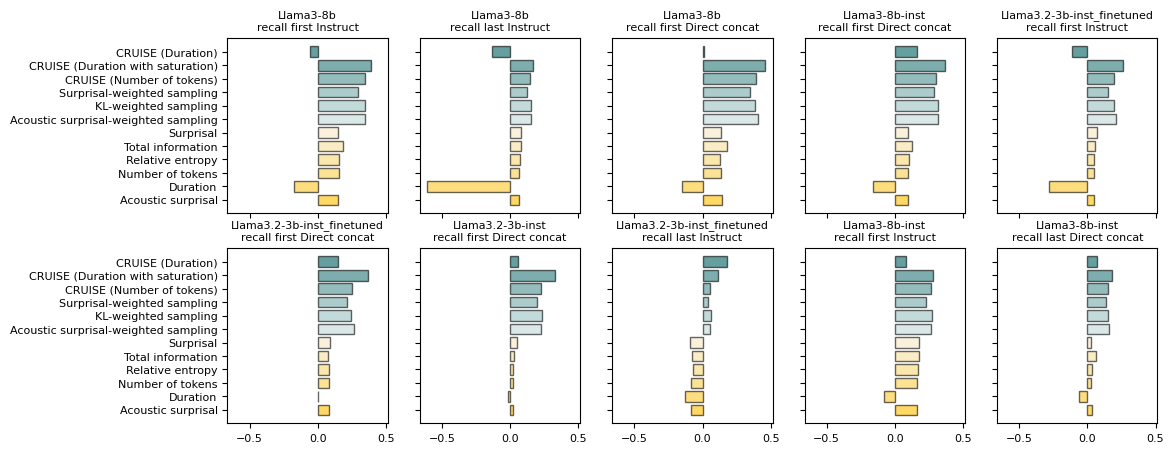

In [55]:
fig,axes = plt.subplots(nrows = 2, ncols = 5,figsize = (12,5),sharey=True,sharex = True)

for i,(rank,ax) in enumerate(zip(np.arange(1,11),axes.flatten())):
    estimate_df = merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing.loc[merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing['composite_rank']==rank]
    colors = [all_colors[p] for p in estimate_df['pred']]
    bars = ax.barh(estimate_df['pred_labels'][::-1], estimate_df['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
    model = np.unique(estimate_df['model_plotting_name'])[0]
    pred_labels = estimate_df['pred_labels']
    recall_first_str = 'recall last' if 'last' in np.unique(estimate_df['target'])[0] else 'recall first'
    inst_str = np.unique(estimate_df['version'])[0]
    ax.set_title(model+'\n'+recall_first_str+' '+inst_str,fontsize =plot_fontsize)
    ax.set_yticks(pred_labels[::-1])
    ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)


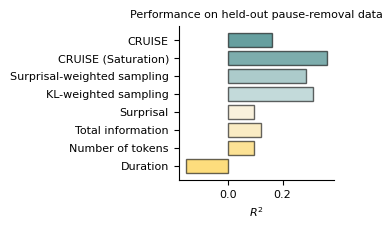

In [56]:
fig,ax = plt.subplots(figsize = (2,2))
estimate_df = merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing.loc[merged_rank_metrics_df_allpreds_shrink_sr_split_by_timing['composite_rank']==4]
estimate_df_mini = estimate_df[estimate_df['pred'].isin(all_preds_mini)].copy()
estimate_df_mini['pred_labels_sm'] = [plotting_label_dict_sm[p] for p in estimate_df_mini['pred']]
colors = [all_colors[p] for p in estimate_df_mini['pred']]
bars = ax.barh(estimate_df_mini['pred_labels_sm'][::-1], estimate_df_mini['r2'][::-1],color=colors[::-1], edgecolor='black',alpha = 0.6)
#     if model=='Llama3-8b-instruct':
#         ax.set_title(model_plotting_names[model],fontsize =plot_fontsize,fontweight='bold')
#     else:
model = np.unique(estimate_df_mini['model_plotting_name'])[0]
pred_labels = estimate_df_mini['pred_labels_sm']
recall_first_str = 'recall last' if 'last' in np.unique(estimate_df_mini['target'])[0] else 'recall first'
inst_str = np.unique(estimate_df_mini['version'])[0]
ax.set_title('Performance on held-out pause-removal data',fontsize =plot_fontsize)
ax.set_yticks(pred_labels[::-1])
ax.set_yticklabels(pred_labels[::-1],fontsize = plot_fontsize)
ax.tick_params(axis='x', labelsize=plot_fontsize)
ax.set_xlabel(r'$R^2$', fontsize = plot_fontsize)
sns.despine()

this_figure_save_dir = os.path.join(save_dir,'llama3-8b-instruct/uniform_encoding/figures_even_split/adjusted')
fig.savefig(os.path.join(this_figure_save_dir,'uniform_encoding_r2_bar_%s_%s_held_out_shrink_mini.svg'%('recall first','direct concatenation')),transparent = True)

## which predictors can predict the change in memory before/after? (split by tokens)

### change in memory 

In [57]:
def make_long_df(df_original,df_shrink,var):
    df_original_sel = df_original.loc[:,['story', 'chunk_type','chunk_type_sr',var]].copy()
    df_shrink_sel = df_shrink.loc[:,['story', 'chunk_type','chunk_type_sr',var]].copy()
    df_original_sel['window_id'] = df_original_sel.index
    df_shrink_sel['window_id'] = df_shrink_sel.index
    df_original_sel['condition'] = 'original'
    df_shrink_sel['condition'] = 'shrink'
    df_long = pd.concat([df_original_sel,df_shrink_sel],ignore_index = True)
    return df_long

In [58]:
all_models_mixedlm_df = []
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    all_concat_dfs_split_by_token_original_sr = all_models_all_concat_dfs_split_by_token[model_name]['original_sr']
    all_concat_dfs_split_by_token_shrink_sr = all_models_all_concat_dfs_split_by_token[model_name]['shrink_sr']
    
    for target in memory_targets:
        df_long =make_long_df(all_concat_dfs_split_by_token_original_sr,all_concat_dfs_split_by_token_shrink_sr,target)
        model = mixedlm(
            "%s ~ condition * chunk_type + story"%target,
            data=df_long,
            groups=df_long["window_id"]
        ).fit()
        #print(model.summary())
        params = model.params
        pvals = model.pvalues

        # main effects
        condition_terms = [k for k in params.index if k.startswith("condition[") and ':' not in k]
        chunk_terms = [k for k in params.index if k.startswith("chunk_type[")]

        # interaction
        interaction_terms = [k for k in params.index if "condition[" in k and "chunk_type[" in k]

        rows = []
        for term in condition_terms + chunk_terms + interaction_terms:
            rows.append({
                "term": term,
                "coef": params[term],
                "pval": pvals[term],
                "sig": pvals[term] < 0.05,
                "target":target,
                "model":model_name
            })

        results_df = pd.DataFrame(rows)
        all_models_mixedlm_df.append(results_df)
all_models_mixedlm_df = pd.concat(all_models_mixedlm_df,ignore_index = True)

In [59]:
merged_mixedlm_memory = pd.merge(left = all_models_mixedlm_df,right = composite_df_z,on = ['target','model'])

In [60]:
def get_significance(p_val):
    if p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    else:
        return "ns"
    

                              sum_sq     df         F    PR(>F)
C(chunk_type)             681.740724    1.0  4.269023  0.040023
C(story)                 3697.402788    7.0  3.307562  0.002315
C(chunk_type):C(story)    371.323779    7.0  0.332173  0.938681
Residual                34014.991316  213.0       NaN       NaN
                              sum_sq     df         F    PR(>F)
C(chunk_type)             398.825661    1.0  2.601776  0.108225
C(story)                 3641.622566    7.0  3.393780  0.001859
C(chunk_type):C(story)    487.751053    7.0  0.454556  0.866371
Residual                32650.723120  213.0       NaN       NaN


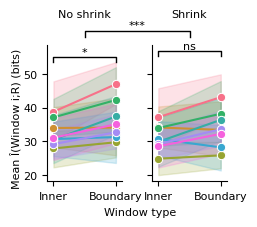

In [61]:
import matplotlib.transforms as transforms

model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(3.1, 2.1), sharey=True)
fig.subplots_adjust(wspace=0.4)

for (condition, ax) in zip(['original_sr', 'shrink_sr'], axes):
    all_concat_df = all_concat_dfs_split_by_token[condition]
    model = ols('mean_ER_intersect ~ C(chunk_type) + C(story) + C(chunk_type):C(story)', data=all_concat_df).fit()
    anova_table = sm.stats.anova_lm(model, typ=2) 
    chunk_type_pval = anova_table['PR(>F)']['C(chunk_type)']
    print(anova_table)

    sns.lineplot(x='chunk_type', y='mean_ER_intersect', 
                 hue='story', 
                 data=all_concat_df, 
                 marker='o',
                 estimator='mean',
                 palette=sns.color_palette("husl", len(stories)),
                 legend=False, ax=ax)

    ax.set_xlim([-0.1, 1.1])
    x1, x2 = 0, 1  # Positions of the two categories in 'chunk_type'
    ymin, ymax = ax.get_ylim() # Changed from plt.gca() to ax to be safe
    
    # Within-panel bracket
    h = (ymax - ymin) * 0.04
    y = ymax - h  
    col = 'black' 
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1, c=col)
    sig_text = get_significance(chunk_type_pval)
    ax.text((x1+x2)*.5, y+h, sig_text, ha='center', va='bottom', color=col, fontsize=plot_fontsize)
    
    sns.despine()
    ax.tick_params(axis='x', labelsize=plot_fontsize)
    ax.tick_params(axis='y', labelsize=plot_fontsize)
    ax.set_xlabel('')
    ax.set_ylabel('')


fig.supxlabel('Window type', fontsize=plot_fontsize,y = 0.03)
fig.supylabel('Mean Î(Window i;R) (bits)', fontsize=plot_fontsize,x = 0.08)
# Layout adjustments moved outside the loop so they don't fight each other
plt.subplots_adjust(left=0.20, right=0.78, bottom=0.2, top=0.85) # Reduced top slightly to give space for cross-panel bar


# ==========================================
# NEW: ADD CROSS-PANEL SIGNIFICANCE BRACKET
# ==========================================
# ==========================================
# UPDATED: ADD CROSS-PANEL SIGNIFICANCE BRACKET (MATCHING HEIGHT)
# ==========================================

# ==========================================
# FIXED: CROSS-PANEL BRACKET (NO SQUEEZING)
# ==========================================
from matplotlib.lines import Line2D

# 1. Grab the top point of your within-panel bracket in data units
within_bracket_top_y = ymax 

# Convert the top and base of your within-panel bracket line into figure coordinates
# to calculate exactly how tall 'h' looks in figure space.
pt_base = fig.transFigure.inverted().transform(axes[0].transData.transform((0.5, y)))
pt_top = fig.transFigure.inverted().transform(axes[0].transData.transform((0.5, y + h)))

# The exact height of your original ticks in figure-coordinate fraction
cross_h = pt_top[1] - pt_base[1] 

# 2. Get the horizontal center coordinates for panel 0 and panel 1
left_panel_top = fig.transFigure.inverted().transform(axes[0].transData.transform((0.5, within_bracket_top_y)))
right_panel_top = fig.transFigure.inverted().transform(axes[1].transData.transform((0.5, within_bracket_top_y)))

fx1, fy1 = left_panel_top[0], left_panel_top[1]
fx2, fy2 = right_panel_top[0], right_panel_top[1]

# Position the cross-bar safely above the individual brackets
cross_y = max(fy1, fy2) + (cross_h * 2.5) 

# 3. Create and add the bracket line directly to the figure (avoids layout squeezing)
bracket_line = Line2D(
    [fx1, fx1, fx2, fx2], 
    [cross_y - cross_h, cross_y, cross_y, cross_y - cross_h], 
    lw=1, color='black', transform=fig.transFigure, zorder=10
)
fig.add_artist(bracket_line)

# 4. Add the cross-panel significance text directly to the figure
cross_condition_pval = merged_mixedlm_memory.loc[(merged_mixedlm_memory['term']=='condition[T.shrink]') & (merged_mixedlm_memory['target']=='mean_ER_intersect') & (merged_mixedlm_memory['model']==model_name)]['pval'].values[0]
cross_sig_text = get_significance(cross_condition_pval)

fig.text(
    (fx1 + fx2) * 0.5, 
    cross_y + (cross_h * 0.2), 
    cross_sig_text, 
    ha='center', va='bottom', color='black', fontsize=plot_fontsize, transform=fig.transFigure, zorder=10
)

# Titles corresponding to axes[0] and axes[1]
titles = ['No shrink', 'Shrink'] 

# Calculate the title vertical position based on the cross-bar position + significance text space
title_y = cross_y + (cross_h * 2.2) 

# Place titles dynamically over the horizontal center of each panel
fig.text(fx1, title_y, titles[0], ha='center', va='bottom', color='black', fontsize=plot_fontsize, transform=fig.transFigure)
fig.text(fx2, title_y, titles[1], ha='center', va='bottom', color='black', fontsize=plot_fontsize,transform=fig.transFigure)

this_figure_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'uniform_encoding','figures_even_split_by_tokens_factor_%.1f_adjusted'%factor)
#plt.savefig(os.path.join(this_figure_save_dir,'mean_recalled_info_recall_first_sr_exp_crossbar.svg'), transparent=True)

### which models show the window type and shinking effects in memory? 

In [62]:
all_models_mixedlm_df_pred = []
for model_name in model_names:
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    all_concat_dfs_split_by_token = all_models_all_concat_dfs_split_by_token[model_name]
    all_concat_dfs_split_by_token_original_sr = all_models_all_concat_dfs_split_by_token[model_name]['original_sr']
    all_concat_dfs_split_by_token_shrink_sr = all_models_all_concat_dfs_split_by_token[model_name]['shrink_sr']
    min_model_rank = composite_df_z.loc[composite_df_z['model']==model_name]['composite_rank'].min()

    for pred in all_preds:
        if 'variable' in pred or 'capacity' in pred or 'saturation' in pred:
            sub_df = composite_df_z[composite_df_z['model'] == model_name]
            # 2. Find the 'target' associated with the minimum 'composite_rank'
            best_target = sub_df.loc[sub_df['composite_rank'].idxmin(), 'target']
            pred_name = pred+'_'+best_target
        else:
            pred_name = pred

        df_long =make_long_df(all_concat_dfs_split_by_token_original_sr,all_concat_dfs_split_by_token_shrink_sr,pred_name)
        model = mixedlm(
            "%s ~ condition * chunk_type + story"%pred_name,
            data=df_long,
            groups=df_long["window_id"]
        ).fit()
        #print(model.summary())
        params = model.params
        pvals = model.pvalues

        # main effects
        condition_terms = [k for k in params.index if k.startswith("condition[") and ':' not in k]
        chunk_terms = [k for k in params.index if k.startswith("chunk_type[")]

        # interaction
        interaction_terms = [k for k in params.index if "condition[" in k and "chunk_type[" in k]

        rows = []
        for term in condition_terms + chunk_terms + interaction_terms:
            rows.append({
                "term": term,
                "coef": params[term],
                "pval": pvals[term],
                "sig": pvals[term] < 0.05,
                "pred":pred,
                "model":model_name,
                "min_composite_rank":min_model_rank
            })

        results_df = pd.DataFrame(rows)
        all_models_mixedlm_df_pred.append(results_df)
    #     if pred =='weighted_event_info_exponential_saturation' and model_name =='Llama3-8b':
    #         print(pred_name)
    #         print(model.summary())
    #         break
    # if model_name =='Llama3-8b':
    #     break
all_models_mixedlm_df_pred = pd.concat(all_models_mixedlm_df_pred,ignore_index = True)

In [63]:
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
llama_models = [
    'Llama3-8b',
    'Llama3-8b-instruct',
    'Llama3.2-3b-instruct',
    'Llama3.2-3b-instruct_finetuned'
]
other_models = ['gemma-2-9b-it', 'mistral-7b-instruct']

llama_colors = sns.color_palette("Blues", n_colors=5)[1:][::-1]
other_colors = sns.color_palette("Set2", n_colors=2)

model_colors = {m:c for m,c in zip(llama_models+other_models, llama_colors+other_colors)}

def plot_heatmap_with_strips_model_only(df, all_preds, plotting_label_dict,
                            model_colors,title):

    df = df.copy()

    # --- build matrix
    mat = df.pivot_table(
        index='pred',
        columns='min_composite_rank',
        values='sig'
    )

    mat = mat.reindex(all_preds)
    mat = mat.sort_index(axis=1)

    # clean labels
    mat.columns = mat.columns.round().astype(int)
    mat.index = [plotting_label_dict.get(p, p) for p in mat.index]
    rank_labels = df['min_composite_rank'].round().astype(int).values

    # --- extract column-wise metadata (aligned with columns)
    col_meta = (
        df.sort_values('min_composite_rank')
          .drop_duplicates('min_composite_rank')
          .set_index('min_composite_rank')
          .loc[mat.columns]
    )

    col_models = col_meta['model'].values


    # --- convert to RGB arrays
    model_color_row = np.array([to_rgb(model_colors[m]) for m in col_models])
    #print(model_color_row.shape)


    strip = np.expand_dims(model_color_row,0) # (1, N, 3)

    
    # Convert to numpy to avoid pandas IndexingErrors
    mat_values = mat.values 

 
    # --- plot
    fig, ax = plt.subplots(figsize=(6, 3.5))

    # Binary colormap: Light Grey for False, Deep Wine for True
    binary_cmap = ["#E0E0E0", "#066327"] 

    sns.heatmap(
        mat,
        ax=ax,
        cmap=binary_cmap,
        xticklabels=mat.columns, # Use the ranks as labels
        yticklabels=mat.index,
        cbar_kws={"ticks": [0, 1], "aspect": 5, "pad": 0.02},
        linewidths=1.0,           # Add separation between cells
        linecolor='white'         # Color of the separating lines
    )


    cbar = ax.collections[0].colorbar
    cbar.set_label(r'p<0.05', fontsize=plot_fontsize)

    ax.set_xlabel('Min model composite metric rank (lower = better)',fontsize = plot_fontsize)
    ax.set_title(title,fontsize = plot_fontsize)
    ax.tick_params(axis='y', labelsize=plot_fontsize)
    ax.tick_params(axis='x', labelsize=plot_fontsize)
    ax.set_ylabel('Predictor',fontsize = plot_fontsize)

    # --- add strip 
    ax_strip = ax.inset_axes([0, 1.05, 1, 0.12])  # [x, y, width, height]
    ax_strip.imshow(strip, aspect='auto')
    ax_strip.set_xticks([])
    ax_strip.set_yticks([0])
    ax_strip.set_yticklabels(['Model'],fontsize = plot_fontsize)

    # --- legends
    # model legend
    model_handles = [
        Patch(facecolor=c, edgecolor='none', label=m)
        for m, c in model_colors.items()
    ]

    fig.legend(handles=model_handles, title="Model",
               loc='upper left', bbox_to_anchor=(1.02, 1))

    sns.despine()
    plt.tight_layout()
    plt.show()

In [64]:
condition_terms = [k for k in all_models_mixedlm_df_pred['term'].unique() if k.startswith("condition[") and ':' not in k]
condition_subdf = all_models_mixedlm_df_pred.loc[all_models_mixedlm_df_pred['term'].isin(condition_terms)]

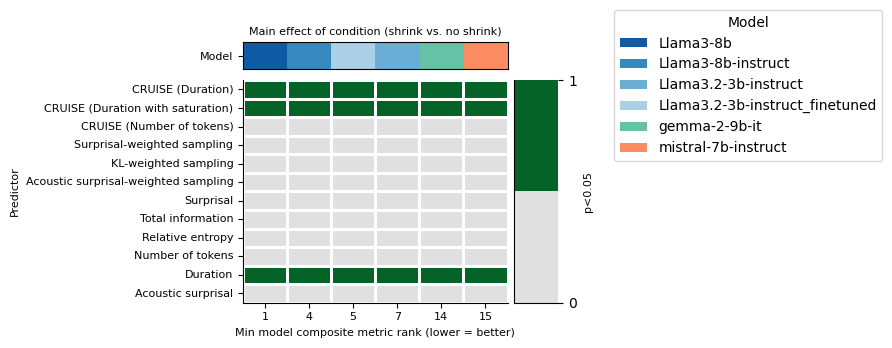

In [65]:
plot_heatmap_with_strips_model_only(condition_subdf, all_preds, plotting_label_dict,
                            model_colors,title='Main effect of condition (shrink vs. no shrink)')

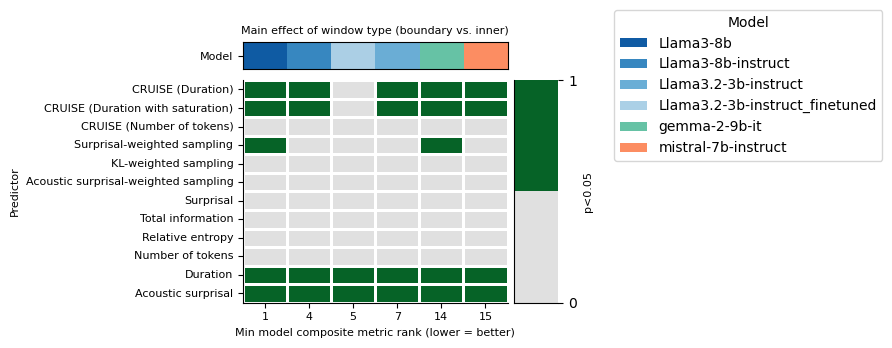

In [66]:
chunk_terms = [k for k in all_models_mixedlm_df_pred['term'].unique() if k.startswith("chunk_type[")]
chunk_subdf = all_models_mixedlm_df_pred.loc[all_models_mixedlm_df_pred['term'].isin(chunk_terms)]
plot_heatmap_with_strips_model_only(chunk_subdf, all_preds, plotting_label_dict,
                            model_colors,title='Main effect of window type (boundary vs. inner)')

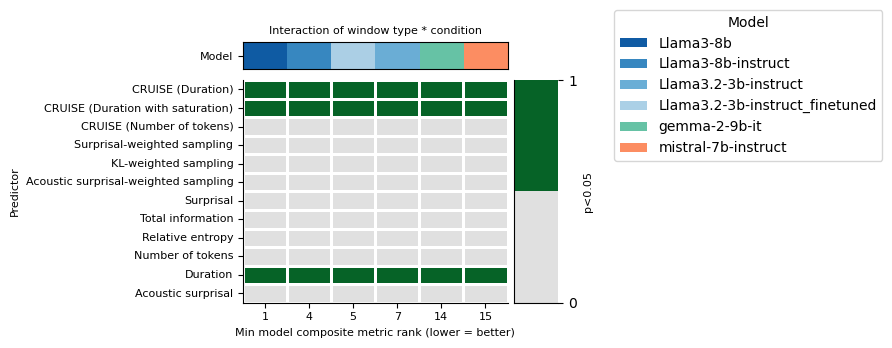

In [67]:
interaction_terms = [k for k in all_models_mixedlm_df_pred['term'].unique() if ("condition[" in k and "chunk_type[" in k)]
interaction_subdf = all_models_mixedlm_df_pred.loc[all_models_mixedlm_df_pred['term'].isin(interaction_terms)]
plot_heatmap_with_strips_model_only(interaction_subdf, all_preds, plotting_label_dict,
                            model_colors,title='Interaction of window type * condition')

In [68]:
sel_model_pred_mixedlm_df =all_models_mixedlm_df_pred.loc[all_models_mixedlm_df_pred['model']==model_name]
sel_model_memory_mixedlm_df = merged_mixedlm_memory.loc[(merged_mixedlm_memory['model']==model_name) & (merged_mixedlm_memory['target']=='mean_ER_intersect')]

In [69]:
target_cols = sel_model_pred_mixedlm_df.columns

# 2. Prepare df2: 
# Rename a placeholder or specific column to 'pred' (naming it 'recall' as requested)
# Then filter it to only include the target columns
sel_model_memory_mixedlm_df_temp = sel_model_memory_mixedlm_df.copy()
sel_model_memory_mixedlm_df_temp['pred'] = 'recall'
sel_model_memory_mixedlm_df_temp.rename(columns ={'composite_rank':'min_composite_rank'},inplace = True)
sel_model_memory_mixedlm_df_temp = sel_model_memory_mixedlm_df_temp[target_cols]

# 3. Merge (Concatenate) them together
merged_df = pd.concat([sel_model_pred_mixedlm_df, sel_model_memory_mixedlm_df_temp], ignore_index=True)

In [74]:
def plot_heatmap_terms(df, all_preds, plotting_label_dict, title,save = None):

    df = df.copy()

    # --- nicer term labels
    term_label_dict = {
        'condition[T.shrink]': 'Pause removal',
        'chunk_type[T.Inner]': 'Boundary',
        'condition[T.shrink]:chunk_type[T.Inner]': 'Interaction'
    }

    # preserve ordering from dataframe
    term_order = df['term'].drop_duplicates().values

    # --- build matrix
    mat = df.pivot_table(
        index='pred',
        columns='term',
        values='sig'
    )

    mat = mat.reindex(all_preds)
    mat = mat[term_order]

    # clean labels
    mat.index = [plotting_label_dict.get(p, p) for p in mat.index]
    xtick_labels = [term_label_dict.get(t, t) for t in mat.columns]

    # --- plot
    fig, ax = plt.subplots(figsize=(1,2.5))

    binary_cmap = ["#E0E0E0", "#066327"]

    sns.heatmap(
        mat,
        ax=ax,
        cmap=binary_cmap,
        xticklabels=xtick_labels,
        yticklabels=mat.index,
        cbar_kws={"ticks": [0, 1], "aspect": 5, "pad": 0.02}, # Keeps the ticks at 0 and 1 locations
        linewidths=1.0,
        linecolor='white'
    )

    # --- colorbar
    cbar = ax.collections[0].colorbar
    cbar.set_label(r'p < 0.05', fontsize=plot_fontsize)
    cbar.set_ticklabels(['False', 'True'], fontsize=plot_fontsize) # <-- ADDED THIS LINE

    # --- labels
    ax.set_xlabel('Effect term', fontsize=plot_fontsize)
    ax.set_ylabel('', fontsize=plot_fontsize)

    ax.set_title(title, fontsize=plot_fontsize)

    ax.tick_params(axis='y', labelsize=plot_fontsize)
    ax.set_xticklabels(
        xtick_labels,
        rotation=45,
        ha='right',
        rotation_mode='anchor',
        fontsize = plot_fontsize
    )
    ax.set_yticklabels(
        mat.index, 
        rotation=45, 
        ha='right', 
        rotation_mode='anchor',
        fontsize=plot_fontsize
    )

    sns.despine()
    plt.tight_layout()
    if save is not None:
        plt.savefig(save,transparent = True)
    plt.show()

/tmp/ipykernel_3604598/414902704.py:73: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


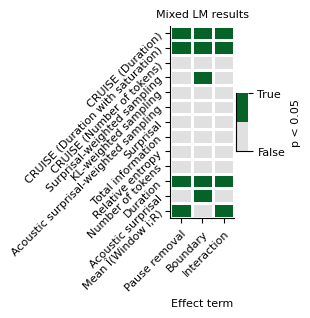

In [75]:
plot_heatmap_terms(merged_df, all_preds+['recall'], plotting_label_dict,
                            title='Mixed LM results')